In [1]:
# ============================================================
# DGX CONFIGURATION — RUN THIS CELL FIRST AFTER RESTARTING KERNEL
# Warwick QU / GlaS binary gland segmentation
# ============================================================
import os
GPU_ID = "3"  # physical DGX GPU; visible to TensorFlow as /GPU:0
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import glob
import random
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

# -------------------------
# Dataset and model settings
# -------------------------
ROOT_DIR = Path("/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED")
IMG_HEIGHT = 256
IMG_WIDTH = 384
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)  # (height, width)
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE_PX = 2
BOUNDARY_TOLERANCE = BOUNDARY_TOLERANCE_PX
PRED_THRESHOLD = 0.5
BASE_FILTERS = [32, 64, 128, 256, 512]  # full-width U-Net++ encoder/decoder schedule
OUTPUT_DIR = "/raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "predicted_masks"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "prediction_visualizations"), exist_ok=True)

# Compatibility aliases: train directories only. Split-aware code below uses SPLIT_DIRS.
IMAGE_DIR = str(ROOT_DIR / "train" / "img")
MASK_DIR = str(ROOT_DIR / "train" / "mask")
SPLIT_DIRS = {
    split: {
        "img": ROOT_DIR / split / "img",
        "mask": ROOT_DIR / split / "mask",
    }
    for split in ("train", "val", "test")
}

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

# GPU check + memory growth. Full paper-width filters are intentionally retained.
physical_gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow version:", tf.__version__)
print("Requested physical GPU ID:", GPU_ID)
print("TensorFlow-visible GPUs:", physical_gpus)
if not physical_gpus:
    raise RuntimeError(
        "TensorFlow sees no GPU. Restart the kernel and launch Jupyter from the DGX "
        "terminal with the appropriate NVIDIA LD_LIBRARY_PATH and CUDA_VISIBLE_DEVICES."
    )
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory-growth setting:", exc)
with tf.device("/GPU:0"):
    _gpu_test = tf.matmul(tf.random.normal((128, 128)), tf.random.normal((128, 128)))
print("GPU matrix test device:", _gpu_test.device)
del _gpu_test

if not ROOT_DIR.is_dir():
    raise FileNotFoundError(f"Dataset root not found: {ROOT_DIR}")
for split, paths in SPLIT_DIRS.items():
    for kind, folder in paths.items():
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing {split}/{kind} directory: {folder}")

print("Dataset root:", ROOT_DIR)
print("Output directory:", OUTPUT_DIR)
for split, paths in SPLIT_DIRS.items():
    print(f"{split:5s} | images={sum(p.is_file() for p in paths['img'].iterdir())} | masks={sum(p.is_file() for p in paths['mask'].iterdir())}")
print("Input tensor shape:", (IMG_HEIGHT, IMG_WIDTH, 3))
print("U-Net++ filter schedule:", BASE_FILTERS)


2026-10-20 01:38:40.573053: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 01:38:40.573105: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 01:38:40.574465: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-20 01:38:40.582653: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-20 01:38:41.518517: W tensorflow/compiler/tf2

TensorFlow version: 2.15.1
Requested physical GPU ID: 3
TensorFlow-visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-20 01:38:44.308686: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30943 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:0b:00.0, compute capability: 7.0


GPU matrix test device: /job:localhost/replica:0/task:0/device:GPU:0
Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Output directory: /raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs
train | images=133 | masks=133
val   | images=16 | masks=16
test  | images=16 | masks=16
Input tensor shape: (256, 384, 3)
U-Net++ filter schedule: [32, 64, 128, 256, 512]


In [2]:
# ============================================================
# SPLIT-AWARE IMAGE/MASK PAIRING + INPUT PIPELINE
# Each split has img/ and mask/; e.g. testA_47.png pairs with testA_47_anno.png.
# The existing train/val/test split is preserved exactly; no random split is made.
# ============================================================
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".bm", ".tif", ".tiff"}


def canonical_mask_stem(path):
    """Remove the Warwick QU annotation suffix from mask names."""
    stem = Path(path).stem
    if stem.lower().endswith("_anno"):
        stem = stem[:-5]
    return stem


def get_pairs(image_dir, mask_dir, split_name="dataset"):
    image_dir, mask_dir = Path(image_dir), Path(mask_dir)
    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    )
    mask_map = {}
    for path in sorted(mask_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in VALID_EXTS:
            continue
        stem = canonical_mask_stem(path)
        if stem in mask_map:
            raise ValueError(
                f"Duplicate masks map to the same image stem '{stem}' in {mask_dir}: "
                f"{mask_map[stem].name}, {path.name}"
            )
        mask_map[stem] = path

    pairs = []
    missing_masks = []
    used_mask_stems = set()
    for img_path in image_paths:
        stem = img_path.stem
        mask_path = mask_map.get(stem)
        if mask_path is None:
            missing_masks.append(img_path.name)
            continue
        pairs.append((str(img_path), str(mask_path)))
        used_mask_stems.add(stem)

    extra_masks = sorted(set(mask_map) - used_mask_stems)
    print(
        f"{split_name}: images={len(image_paths)}, masks={len(mask_map)}, "
        f"paired={len(pairs)}, missing_masks={len(missing_masks)}, extra_masks={len(extra_masks)}"
    )
    if missing_masks:
        raise ValueError(
            f"{split_name}: no matching mask for {len(missing_masks)} image(s). "
            f"Examples: {missing_masks[:10]}. Expected image.png / image_anno.png pairing."
        )
    if extra_masks:
        print(f"Warning: {split_name} has masks without an image, e.g. {extra_masks[:10]}")
    if not pairs:
        raise ValueError(f"No image-mask pairs found for split '{split_name}'.")
    return pairs


train_pairs = get_pairs(SPLIT_DIRS["train"]["img"], SPLIT_DIRS["train"]["mask"], "train")
val_pairs = get_pairs(SPLIT_DIRS["val"]["img"], SPLIT_DIRS["val"]["mask"], "val")
test_pairs = get_pairs(SPLIT_DIRS["test"]["img"], SPLIT_DIRS["test"]["mask"], "test")
# Convenience concatenation for auditing only; never use it to split the dataset.
pairs = train_pairs + val_pairs + test_pairs


def _path_value(value):
    """Decode paths from tf.numpy_function or accept normal Python strings."""
    if isinstance(value, np.ndarray):
        value = value.item()
    if isinstance(value, (bytes, np.bytes_)):
        value = value.decode("utf-8")
    return os.fspath(value)


def load_image_mask(img_path, mask_path):
    img_path = _path_value(img_path)
    mask_path = _path_value(mask_path)

    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # OpenCV takes (width, height); IMG_SIZE is stored as (height, width).
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)
    # The prepared dataset stores foreground as 255 and background as 0.
    # Keep the mask binary (0/1) for BCE + Dice training.
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)
    return img, mask


def tf_load_image_mask(img_path, mask_path):
    img, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    img.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    mask.set_shape([IMG_HEIGHT, IMG_WIDTH, 1])
    return img, mask


def duplicate_mask(image, mask):
    """Supply a full-resolution mask to each of the 4 deep-supervision outputs."""
    return image, (mask, mask, mask, mask)


def make_dataset(split_pairs, training=False, duplicate=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from zero image-mask pairs.")
    img_paths = [p[0] for p in split_pairs]
    mask_paths = [p[1] for p in split_pairs]
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(split_pairs), seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if duplicate:
        ds = ds.map(duplicate_mask, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds_multi = make_dataset(train_pairs, training=True, duplicate=True)
val_ds_multi = make_dataset(val_pairs, training=False, duplicate=True)
test_ds_multi = make_dataset(test_pairs, training=False, duplicate=True)
train_ds_single = make_dataset(train_pairs, training=True, duplicate=False)
val_ds_single = make_dataset(val_pairs, training=False, duplicate=False)
test_ds_single = make_dataset(test_pairs, training=False, duplicate=False)

print("\nFinal paired sample counts:")
print("Train      :", len(train_pairs))
print("Validation :", len(val_pairs))
print("Test       :", len(test_pairs))
print("Total      :", len(pairs))

# Sanity-check one sample before model creation/training.
_sample_image, _sample_mask = load_image_mask(*train_pairs[0])
print("Sample image shape:", _sample_image.shape, "range:", float(_sample_image.min()), float(_sample_image.max()))
print("Sample mask shape:", _sample_mask.shape, "unique values:", np.unique(_sample_mask))
if not set(np.unique(_sample_mask).tolist()).issubset({0.0, 1.0}):
    raise ValueError("Mask preprocessing did not yield binary 0/1 values.")


train: images=133, masks=133, paired=133, missing_masks=0, extra_masks=0
val: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0
test: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0

Final paired sample counts:
Train      : 133
Validation : 16
Test       : 16
Total      : 165
Sample image shape: (256, 384, 3) range: 0.01568627543747425 1.0
Sample mask shape: (256, 384, 1) unique values: [0. 1.]


Model: "UNetPlusPlus_Train"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 384, 32)         896       ['input_1[0][0]']             
                                                                                                  
 re_lu (ReLU)                (None, 256, 384, 32)         0         ['conv2d[0][0]']              
                                                                                                  
 conv2d_1 (Conv2D)           (None, 256, 384, 32)         9248      ['re_lu[0][0]']               
                                                                                 

2026-10-20 01:39:01.224663: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-20 01:39:04.355785: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f93ee7c92f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-20 01:39:04.355824: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2026-10-20 01:39:04.362506: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792440544.477752   28066 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


133/133 [==============================] - ETA: 0s - loss: 0.8187 - side_1_loss: 0.8185 - side_2_loss: 0.8177 - side_3_loss: 0.8190 - side_4_loss: 0.8194 - side_1_accuracy: 0.5082 - side_1_dice_coef: 0.5512 - side_1_iou_coef: 0.3894 - side_2_accuracy: 0.5083 - side_2_dice_coef: 0.5524 - side_2_iou_coef: 0.3905 - side_3_accuracy: 0.5074 - side_3_dice_coef: 0.5512 - side_3_iou_coef: 0.3894 - side_4_accuracy: 0.5072 - side_4_dice_coef: 0.5521 - side_4_iou_coef: 0.3901
val_avg_loss=0.8545  val_avg_accuracy=0.4845  val_avg_dice_coef=0.5042  val_avg_iou_coef=0.3461

Epoch 1: val_avg_dice_coef improved from -inf to 0.50419, saving model to /raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs/best_unetpp_extra_direct_skips_train.keras
133/133 [==============================] - 35s 74ms/step - loss: 0.8187 - side_1_loss: 0.8185 - side_2_loss: 0.8177 - side_3_loss: 0.8190 - side_4_loss: 0.8194 - side_1_accuracy: 0.5082 - side_1_dice_coef: 0.5512 - side_1_iou_coef: 0.3894 - side_2_accur

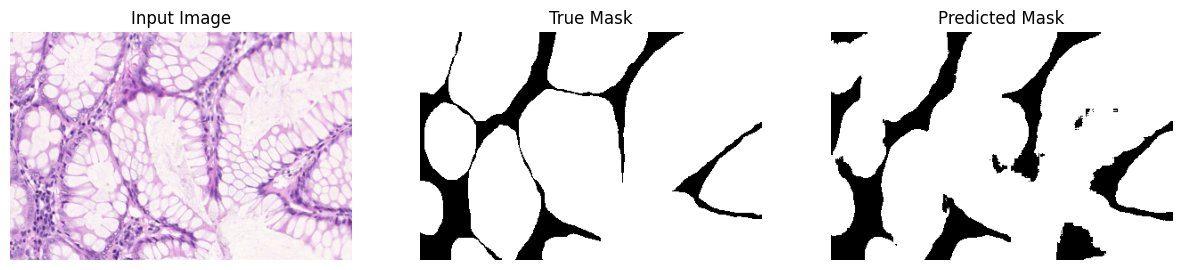

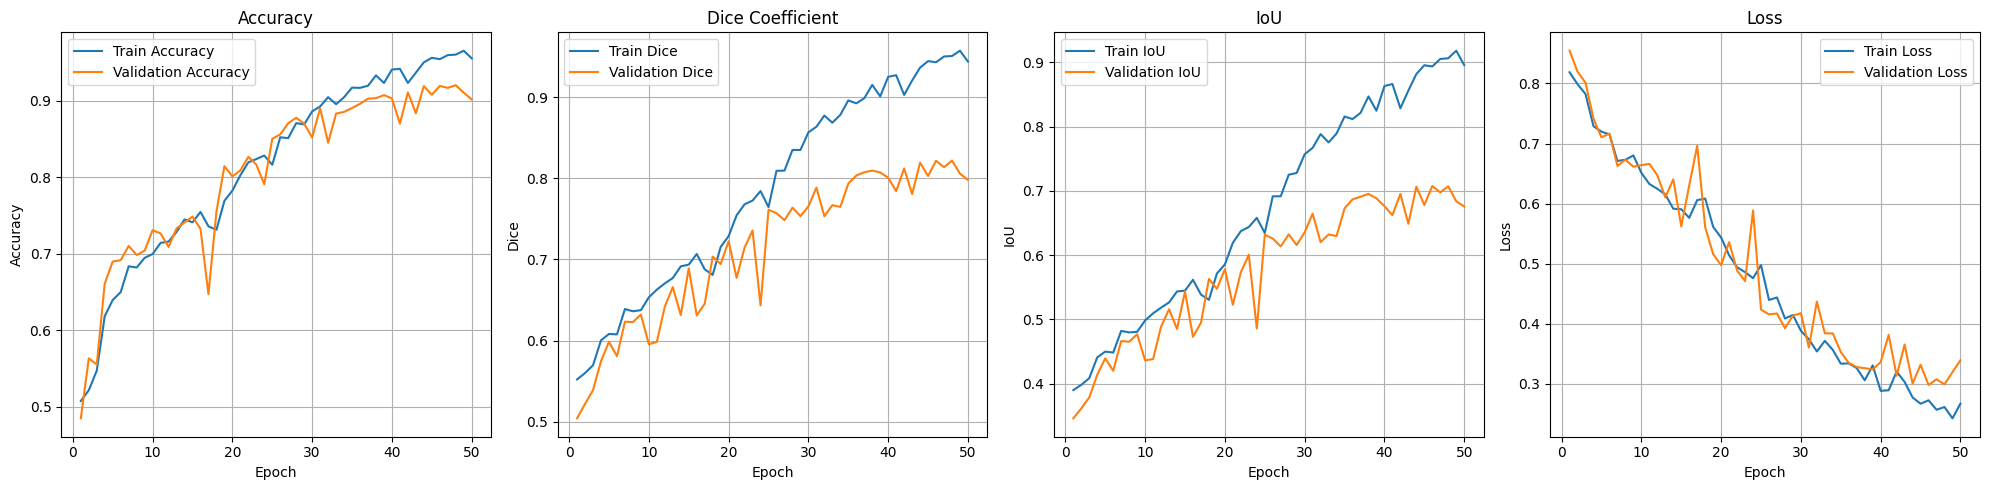

In [3]:
# =========================
# LOSS + METRICS
# =========================
bce_loss_fn = tf.keras.losses.BinaryCrossentropy()

def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_bce_dice_loss(y_true, y_pred):
    bce = bce_loss_fn(y_true, y_pred)
    dloss = dice_loss(y_true, y_pred)
    return 0.5 * bce + dloss

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

# =========================
# UNET++ BLOCKS
# =========================
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    return x

# =========================
# BUILD UNET++ WITH YOUR EXTRA DIRECT SKIPS
# =========================
def build_unet_plus_plus(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    filters = [32, 64, 128, 256, 512]  # full-width U-Net++ filter schedule retained
    depth = len(filters) - 1

    inputs = layers.Input(shape=input_shape)
    X = {}

    # Encoder backbone
    x = inputs
    for i in range(depth + 1):
        X[(i, 0)] = conv_block(x, filters[i])
        if i < depth:
            x = layers.MaxPooling2D((2, 2))(X[(i, 0)])

    # Nested decoder / skip pathways
    for j in range(1, depth + 1):
        for i in range(0, depth - j + 1):
            up = layers.Conv2DTranspose(
                filters[i],
                kernel_size=2,
                strides=2,
                padding="same"
            )(X[(i + 1, j - 1)])

            concat_inputs = [X[(i, k)] for k in range(j)] + [up]

            # Your extra direct skips:
            # X(1,0) -> X(0,4)
            # X(2,0) -> X(1,3)
            # X(3,0) -> X(2,2)
            direct_skip_map = {
                (0, 4): (1, 0),
                (1, 3): (2, 0),
                (2, 2): (3, 0),
            }

            if (i, j) in direct_skip_map:
                si, sj = direct_skip_map[(i, j)]
                direct_up = layers.Conv2DTranspose(
                    filters[i],
                    kernel_size=2,
                    strides=2,
                    padding="same"
                )(X[(si, sj)])
                concat_inputs.append(direct_up)

            x = layers.Concatenate()(concat_inputs)
            X[(i, j)] = conv_block(x, filters[i])

    # Deep supervision outputs
    side_outputs = [
        layers.Conv2D(1, 1, activation="sigmoid", name=f"side_{j}")(X[(0, j)])
        for j in range(1, depth + 1)
    ]

    # Training model returns all 4 side outputs
    train_model = Model(inputs, side_outputs, name="UNetPlusPlus_Train")

    # Accurate inference mode: average the 4 outputs
    avg_output = layers.Average(name="avg_output")(side_outputs)
    infer_model = Model(inputs, avg_output, name="UNetPlusPlus_Infer")

    return train_model, infer_model

train_model, infer_model = build_unet_plus_plus()

train_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=[combined_bce_dice_loss for _ in range(4)],
    loss_weights=[0.25, 0.25, 0.25, 0.25],
    metrics=[
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
    ]
)

infer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=combined_bce_dice_loss,
    metrics=[
        "accuracy",
        dice_coef,
        iou_coef
    ]
)

train_model.summary()
infer_model.summary()

# =========================
# CALLBACK TO EVALUATE AVERAGED OUTPUT
# =========================
class EvaluateAveragedModel(tf.keras.callbacks.Callback):

    def __init__(self, averaged_model, val_ds):
        super().__init__()
        self.averaged_model = averaged_model
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):

        logs = logs if logs is not None else {}

        results = self.averaged_model.evaluate(
            self.val_ds,
            verbose=0,
            return_dict=True
        )

        logs["val_avg_loss"] = float(results["loss"])
        logs["val_avg_accuracy"] = float(results["accuracy"])
        logs["val_avg_dice_coef"] = float(results["dice_coef"])
        logs["val_avg_iou_coef"] = float(results["iou_coef"])

        print(
            f"\n"
            f"val_avg_loss={logs['val_avg_loss']:.4f}  "
            f"val_avg_accuracy={logs['val_avg_accuracy']:.4f}  "
            f"val_avg_dice_coef={logs['val_avg_dice_coef']:.4f}  "
            f"val_avg_iou_coef={logs['val_avg_iou_coef']:.4f}"
        )

paper_eval_cb = EvaluateAveragedModel(infer_model, val_ds_single)

callbacks = [

    paper_eval_cb,

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unetpp_extra_direct_skips_train.keras"),
        monitor="val_avg_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_avg_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_avg_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )

]

# =========================
# TRAIN
# =========================
history = train_model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Save the averaged inference model (shares the trained weights with train_model).
infer_model_path = os.path.join(OUTPUT_DIR, "final_unetpp_extra_direct_skips_inference.keras")
infer_model.save(infer_model_path)
print("Saved averaged inference model:", infer_model_path)

# =========================
# PLOTS
# =========================
def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)
    plt.figure(figsize=(20,5))

    # ---------------- Accuracy ----------------

    plt.subplot(1,4,1)
    if "side_4_accuracy" in hist:
        plt.plot(
            epochs_range,
            hist["side_4_accuracy"],
            label="Train Accuracy"
        )
    if "val_avg_accuracy" in hist:
        plt.plot(
            epochs_range,
            hist["val_avg_accuracy"],
            label="Validation Accuracy"
        )
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    # ---------------- Dice ----------------

    plt.subplot(1,4,2)
    if "side_4_dice_coef" in hist:
        plt.plot(
            epochs_range,
            hist["side_4_dice_coef"],
            label="Train Dice"
        )
    if "val_avg_dice_coef" in hist:
        plt.plot(
            epochs_range,
            hist["val_avg_dice_coef"],
            label="Validation Dice"
        )
    plt.title("Dice Coefficient")
    plt.xlabel("Epoch")
    plt.ylabel("Dice")
    plt.legend()
    plt.grid(True)

    # ---------------- IoU ----------------
    plt.subplot(1,4,3)
    if "side_4_iou_coef" in hist:
        plt.plot(
            epochs_range,
            hist["side_4_iou_coef"],
            label="Train IoU"
        )
    if "val_avg_iou_coef" in hist:
        plt.plot(
            epochs_range,
            hist["val_avg_iou_coef"],
            label="Validation IoU"
        )
    plt.title("IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    # ---------------- Loss ----------------
    plt.subplot(1,4,4)
    plt.plot(
        epochs_range,
        hist["loss"],
        label="Train Loss"
    )
    if "val_avg_loss" in hist:
        plt.plot(
            epochs_range,
            hist["val_avg_loss"],
            label="Validation Loss"
        )
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =========================
# PREDICTION + VISUALIZATION
# =========================
def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

show_prediction(infer_model, val_pairs[0])
plot_training_curves(history)



Test image 1/16: testB_1.png
  IoU                   : 0.7275
  Recall                : 0.9280
  Precision             : 0.7710
  Dice Coefficient      : 0.8422
  Boundary F1           : 0.4474
  Boundary Recall       : 0.7536
  Boundary Precision    : 0.3181

Test image 2/16: testB_10.png
  IoU                   : 0.6916
  Recall                : 0.8163
  Precision             : 0.8191
  Dice Coefficient      : 0.8177
  Boundary F1           : 0.5271
  Boundary Recall       : 0.7044
  Boundary Precision    : 0.4211

Test image 3/16: testB_11.png
  IoU                   : 0.9122
  Recall                : 0.9404
  Precision             : 0.9682
  Dice Coefficient      : 0.9541
  Boundary F1           : 0.7927
  Boundary Recall       : 0.8914
  Boundary Precision    : 0.7137

Test image 4/16: testB_12.png
  IoU                   : 0.7881
  Recall                : 0.9386
  Precision             : 0.8309
  Dice Coefficient      : 0.8815
  Boundary F1           : 0.5091
  Boundary Recall  

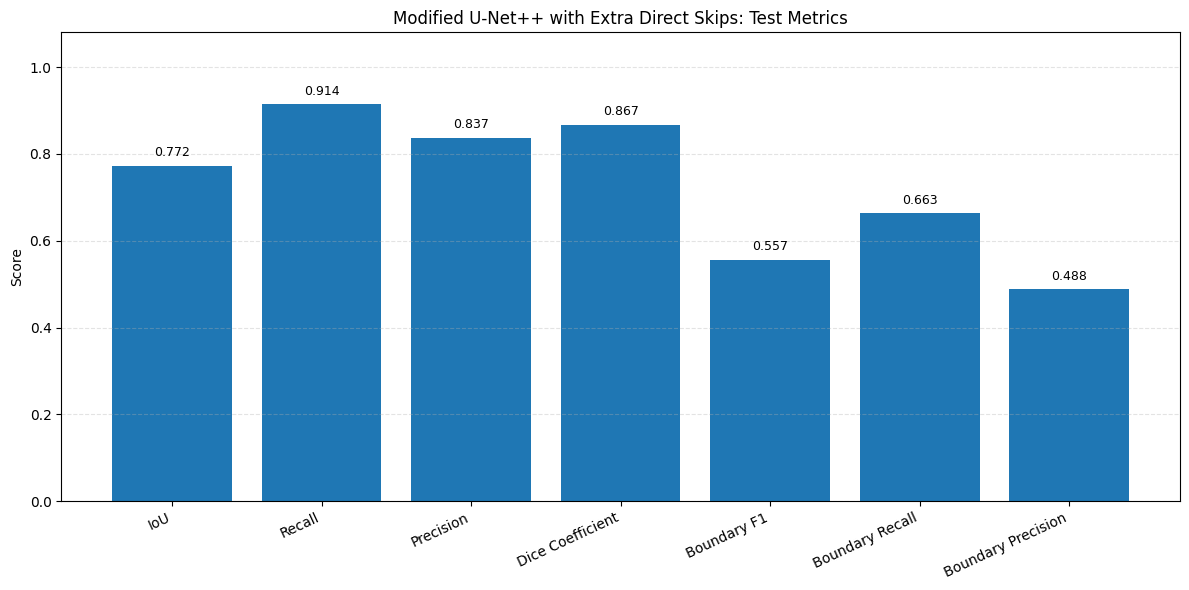

Saved overall graph: /raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs/test_metrics_graph.png


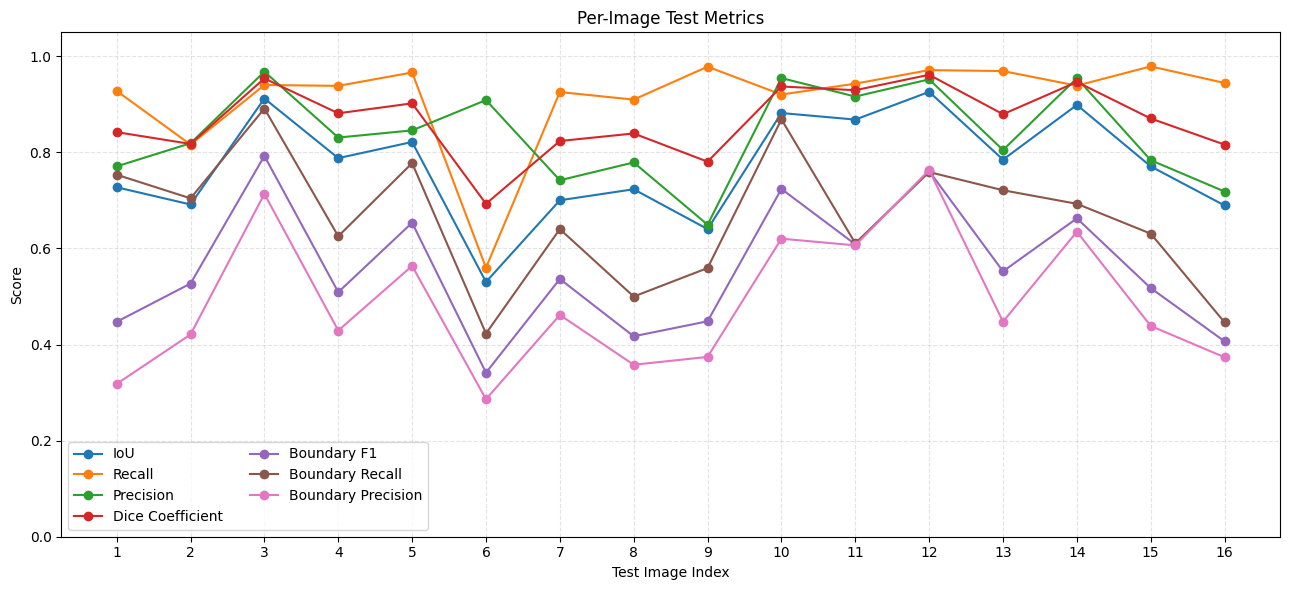

Saved per-image graph: /raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs/test_metrics_per_image_graph.png


In [4]:
# ============================================================
# FINAL VALIDATION EVALUATION
# Pixel + boundary metrics; boundaries are derived only from binary mask.
# Does NOT read or use Boundary_Mask_GT.
# ============================================================
import pandas as pd

PRED_THRESHOLD = 0.5
METRIC_NAMES = [
    "iou", "recall", "precision", "dice_coef",
    "boundary_f1", "boundary_recall", "boundary_precision"
]
DISPLAY_NAMES = [
    "IoU", "Recall", "Precision", "Dice Coefficient",
    "Boundary F1", "Boundary Recall", "Boundary Precision"
]


def extract_binary_boundary(mask):
    mask = (np.asarray(mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(
        mask, np.ones((3, 3), np.uint8), iterations=1,
        borderType=cv2.BORDER_CONSTANT, borderValue=0
    )
    return mask - eroded


def calculate_all_metrics(gt_mask, pred_mask, tolerance=BOUNDARY_TOLERANCE):
    gt = (np.asarray(gt_mask).squeeze() > 0).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Shape mismatch: GT {gt.shape}, prediction {pred.shape}")

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))

    precision = tp / (tp + fp) if (tp + fp) else (1.0 if (tp + fn) == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if (tp + fp) == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    dice = (2 * tp / dice_den) if dice_den else 1.0
    iou_den = tp + fp + fn
    iou = (tp / iou_den) if iou_den else 1.0

    # Boundary extraction from binary ground truth and predicted binary mask.
    gt_boundary = extract_binary_boundary(gt)
    pred_boundary = extract_binary_boundary(pred)
    gt_count = int(gt_boundary.sum())
    pred_count = int(pred_boundary.sum())

    tol = max(0, int(tolerance))
    ksize = 2 * tol + 1
    disk = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    dilated_gt = cv2.dilate(gt_boundary, disk, iterations=1)
    dilated_pred = cv2.dilate(pred_boundary, disk, iterations=1)

    matched_pred = int(np.sum((pred_boundary > 0) & (dilated_gt > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (dilated_pred > 0)))

    boundary_precision = (
        matched_pred / pred_count if pred_count else (1.0 if gt_count == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / gt_count if gt_count else (1.0 if pred_count == 0 else 0.0)
    )
    bf_den = boundary_precision + boundary_recall
    boundary_f1 = 2 * boundary_precision * boundary_recall / bf_den if bf_den else 0.0

    return {
        "iou": float(iou), "recall": float(recall),
        "precision": float(precision), "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


if "infer_model" not in globals() or "test_pairs" not in globals():
    raise RuntimeError("Expected trained infer_model and test_pairs. Run training cells first.")
if len(test_pairs) == 0:
    raise RuntimeError("test_pairs is empty; nothing to evaluate.")

rows = []
for idx, (img_path, mask_path) in enumerate(test_pairs, start=1):
    image, gt_mask = load_image_mask(str(img_path).encode(), str(mask_path).encode())
    pred_prob = infer_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    pred_mask = (np.asarray(pred_prob).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
    gt_binary = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    scores = calculate_all_metrics(gt_binary, pred_mask)
    rows.append({"image": os.path.basename(str(img_path)), **scores})

    print(f"\nTest image {idx}/{len(test_pairs)}: {os.path.basename(str(img_path))}")
    for name, label in zip(METRIC_NAMES, DISPLAY_NAMES):
        print(f"  {label:<22}: {scores[name]:.4f}")

results_df = pd.DataFrame(rows)
mean_scores = results_df[METRIC_NAMES].mean()
print("\n" + "=" * 58)
print("FINAL VALIDATION METRICS (MACRO-AVERAGE)")
print("=" * 58)
for name, label in zip(METRIC_NAMES, DISPLAY_NAMES):
    print(f"{label:<24}: {mean_scores[name]:.4f}")
print(f"Test images: {len(results_df)}")
print(f"Boundary tolerance: {BOUNDARY_TOLERANCE} pixels")

per_image_csv = os.path.join(OUTPUT_DIR, "test_metrics_per_image.csv")
summary_csv = os.path.join(OUTPUT_DIR, "test_metrics_summary.csv")
results_df.to_csv(per_image_csv, index=False)
summary_df = pd.DataFrame({
    "metric": DISPLAY_NAMES,
    "mean_score": [mean_scores[name] for name in METRIC_NAMES]
})
summary_df.to_csv(summary_csv, index=False)
print("\nSaved per-image CSV:", per_image_csv)
print("Saved summary CSV:", summary_csv)

# Graph 1: overall macro-average values with numeric labels.
values = [float(mean_scores[name]) for name in METRIC_NAMES]
plt.figure(figsize=(12, 6))
bars = plt.bar(DISPLAY_NAMES, values)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.title("Modified U-Net++ with Extra Direct Skips: Test Metrics")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
             f"{value:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
overall_graph = os.path.join(OUTPUT_DIR, "test_metrics_graph.png")
plt.savefig(overall_graph, dpi=200, bbox_inches="tight")
plt.show()
print("Saved overall graph:", overall_graph)

# Graph 2: per-image comparison.
plt.figure(figsize=(13, 6))
image_idx = np.arange(1, len(results_df) + 1)
for name, label in zip(METRIC_NAMES, DISPLAY_NAMES):
    plt.plot(image_idx, results_df[name], marker="o", linewidth=1.5, label=label)
plt.ylim(0, 1.05)
plt.xlabel("Test Image Index")
plt.ylabel("Score")
plt.title("Per-Image Test Metrics")
plt.xticks(image_idx)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(ncol=2)
plt.tight_layout()
per_image_graph = os.path.join(OUTPUT_DIR, "test_metrics_per_image_graph.png")
plt.savefig(per_image_graph, dpi=200, bbox_inches="tight")
plt.show()
print("Saved per-image graph:", per_image_graph)


In [5]:
# Save predicted masks for all validation images
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
os.makedirs(PREDICTION_DIR, exist_ok=True)

PRED_THRESHOLD = globals().get("PRED_THRESHOLD", 0.5)

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):

    # Load image using the notebook's existing preprocessing
    image, _ = load_image_mask(
        str(image_path).encode(),
        str(mask_path).encode()
    )

    # U-Net++ averaged inference prediction (sigmoid already applied)
    pred_prob = infer_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0].squeeze()

    # Convert to binary mask: background=0, foreground=255
    pred_mask = (
        (pred_prob >= PRED_THRESHOLD).astype(np.uint8) * 255
    )

    # Save predicted mask as PNG
    filename = (
        f"{os.path.splitext(os.path.basename(str(image_path)))[0]}"
        "_prediction.png"
    )
    save_path = os.path.join(PREDICTION_DIR, filename)

    if not cv2.imwrite(save_path, pred_mask):
        raise IOError(f"Failed to save: {save_path}")

    print(f"[{idx}/{len(val_pairs)}] Saved: {filename}")

print(f"\nAll predicted masks saved in:\n{PREDICTION_DIR}")

[1/16] Saved: testA_1_prediction.png
[2/16] Saved: testA_10_prediction.png
[3/16] Saved: testA_11_prediction.png
[4/16] Saved: testA_12_prediction.png
[5/16] Saved: testA_13_prediction.png
[6/16] Saved: testA_14_prediction.png
[7/16] Saved: testA_15_prediction.png
[8/16] Saved: testA_16_prediction.png
[9/16] Saved: testA_2_prediction.png
[10/16] Saved: testA_3_prediction.png
[11/16] Saved: testA_4_prediction.png
[12/16] Saved: testA_5_prediction.png
[13/16] Saved: testA_6_prediction.png
[14/16] Saved: testA_7_prediction.png
[15/16] Saved: testA_8_prediction.png
[16/16] Saved: testA_9_prediction.png

All predicted masks saved in:
/raid/home/dgx1725/unetpp_mod1_extradirectskip_warwick_outputs/predicted_masks
